# Example Notebook for Streak/linear feature detection and Characterization using Hough-Transform

In [1]:
## Importing necessary libraries

import os
import gdown

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

from astropy.io import fits
from astropy.stats import sigma_clipped_stats

from skimage.transform import resize
from skimage import transform

from scipy.ndimage import  gaussian_laplace, median_filter, map_coordinates
from scipy.optimize import curve_fit

## Loading Sample Frame from Google Drive

In [1]:
## Frames with open access from google drive

id_1 = "1rlsCHAPPA9ZvRyFjFXrn1FNsq-6SO5Vw"  ## Extremely-Faint and narrow  sample   ; remains un-detected
id_2 = "1wjquMjauxM029q_4Q6AOKAdMwN9-P80_"  ## Faint sample                         ; Detected by the algorithm
id_3 = "1Be6BLKhSm9aHECg1OOaGWk9j1yWu_grK"  ## Faint & broad sample                 ; Detected by the algorithm
id_4 = "1DFLcnQMRdNrpHo7TqyIw_EpAJykGB-IO"  ## Bright & Narrow sample               ; remains un-detected
id_5 = "117q2WyhlG9KD2FgubB-Wn9fESXdz99mn"  ## faint & Narrow                       ; Detected by the algorithm
id_6 = "1OqCq6rarkBRn7VXGXNveDgPwkhY_OgTW"  ## Bright, narrow                       ; remains un-detected

In [88]:
# Replace with actual file ID to download
file_id = id_2   ## Chosse any id given in the previous cell
url = f"https://drive.google.com/uc?id={file_id}"

# Download the file
gdown.download(url, "img.FITS", quiet=False)

# Open the FITS file
with fits.open('img.FITS') as hdul:
    img = hdul[0].data
    header = hdul[0].header

Downloading...
From: https://drive.google.com/uc?id=1wjquMjauxM029q_4Q6AOKAdMwN9-P80_
To: /content/img.FITS
100%|██████████| 67.1M/67.1M [00:00<00:00, 194MB/s]


In [89]:
## Loading  samples from local directory

sample_path = r"/content/img.FITS"

## Load the sample path
with fits.open(sample_path) as hdul:
    data = hdul[0].data
    header = hdul[0].header

try:
    # Get the sky Background
    sky = header['SKY']
    data+= sky

except:
    data+= 1190



## Print Essential Information about the sample
print (f'''
Frame Shape = {data.shape}
Filter info = {header['FILTER']}
Date of Obs = {header['DATE-OBS']}
''')


Frame Shape = (4096, 4096)
Filter info = i
Date of Obs = 2023-03-13



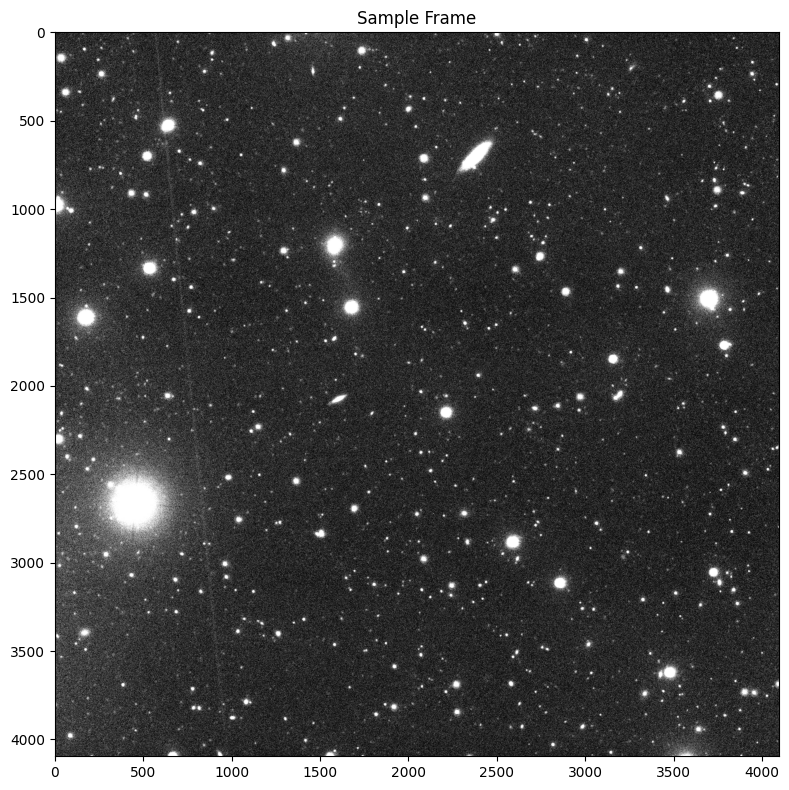

In [ ]:
# ## Visualize the imported Sample

# Get the Sigma Clipped Statistics of the data
mean , median , std = sigma_clipped_stats(data, sigma=3.0)                     

# Plot the data
plt.figure(figsize=(8,8))
plt.imshow(data, cmap='gray', vmin=median-1*std, vmax=median+5*std)
plt.title(f"Sample Frame")
plt.tight_layout()
plt.show()

_________________________

In [91]:
# Make a copy of the sample
image_sample = data.copy()

# PART A : STREAK / TRAIL DETECTION

## STEP 1: Pre-Process the Sample to remove noise such as Cosmic Ray hits and dynamic thresholding

In [92]:
######## Functions to perform pre-processing ###################################

# Function to fill NaN values with median + n_sigma * std
def replace_invalid_pixels(image, median, std):
    """
    Replace NaN, infinite, or invalid pixel values with (median + 4*std).

    """
    replacement_value = median + 4 * std
    cleaned_image = np.array(image, copy=True)
    invalid_mask = ~np.isfinite(cleaned_image)
    cleaned_image[invalid_mask] = replacement_value

    return cleaned_image

# Function to perform Median Filtering : Removing cosmic ray hits
def remove_cosmic_rays(image, kernel_size=3):
    """
    Apply median filtering to remove cosmic ray hits from an astronomical image.
    """
    filtered_image = median_filter(image, size=kernel_size)

    return filtered_image

# Function to perform dynamic thresholding
def process_image(img, high=5, low=0):

    '''
    Pre-process the image by applying sigma clipping and normalizing the pixel values to the range [0, 1].
    '''
    _, m, s = sigma_clipped_stats(img)
    img = replace_invalid_pixels(img, m , s)
    img[img > m + high * s] = m + high * s
    img[img < m - low * s] = m - low * s
    img -= np.min(img)
    img = img / np.max(img)
    return img , m , s


In [93]:
## Perform Preprocessing

# Median Filtering
image_sample_denoised  = remove_cosmic_rays(image_sample)

# Perform dynamic thresholding
image_sample_pre_processed, med_sample, std_sample= process_image(image_sample_denoised)


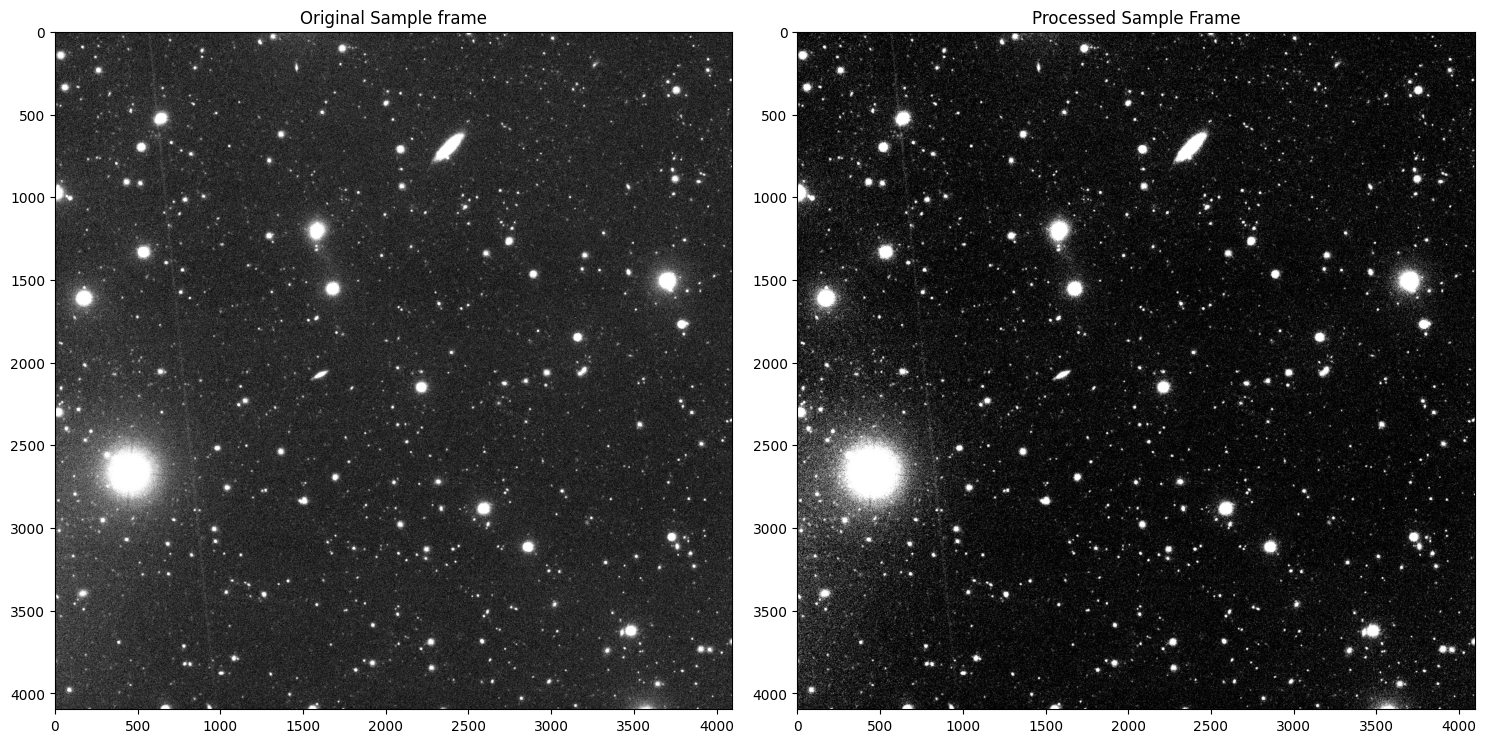

In [94]:
## Visualizing the original frame and the processed frame

fig , ax  = plt.subplots(1,2, figsize = (15 ,30))

# Original frame
ax[0].imshow(data , cmap = 'gray', vmin=median-1*std, vmax=median+5*std)
ax[0].set_title(f"Original Sample frame")

# Processed frame
ax[1].imshow(image_sample_pre_processed , cmap = 'gray', vmin=0, vmax=1)
ax[1].set_title(f"Processed Sample Frame")

plt.tight_layout()
plt.show()

## Step 2: Perform Edge Detection from Processed frame

In [95]:
## Function to perform Edge Detection using Laplacian of Gaussian (LoG) Kernel

def log_edge_detection(image, sigma=15):
    '''
    Apply LoG for Edge Detection
    '''

    # Apply the Laplacian of Gaussian filter
    log_image = gaussian_laplace(image, sigma=sigma)

    # Threshold the LoG image to create a binary edge map
    threshold = np.mean(log_image)
    edges = log_image < threshold

    return edges



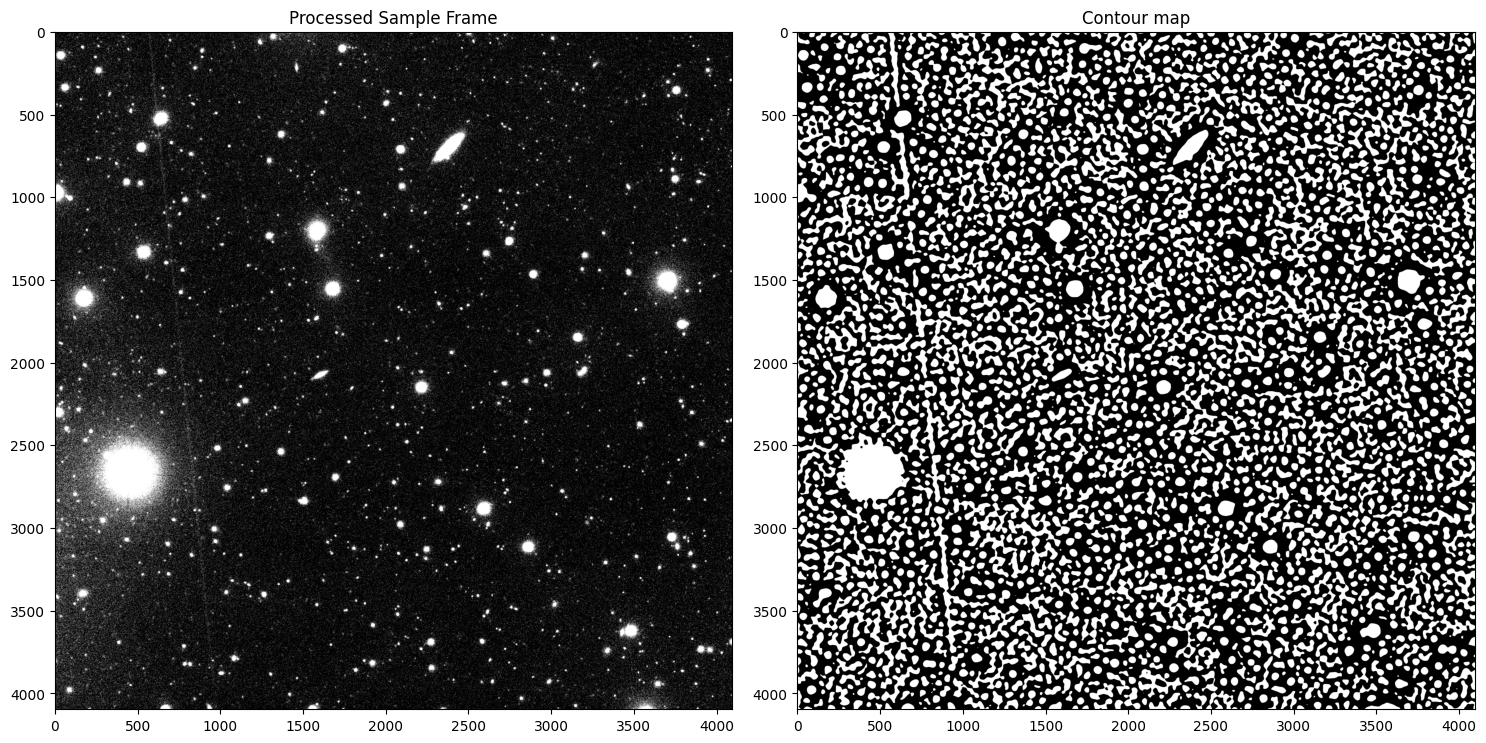

In [96]:
## Perform Edge detection
sample_edge = log_edge_detection(image_sample_pre_processed, sigma = 15)

## Visualize the countour map along with the processed sample
fig , ax  = plt.subplots(1,2, figsize = (15 ,30))

# Processed frame
ax[0].imshow(image_sample_pre_processed , cmap = 'gray', vmin=0, vmax=1)
ax[0].set_title(f"Processed Sample Frame")

# Contour map
ax[1].imshow(sample_edge , cmap = 'gray', vmin=0, vmax=1)
ax[1].set_title(f"Contour map")

plt.tight_layout()
plt.show()


## Step 3: Trail / Streak Detection using Hough Transform

In [97]:
## Function to perform Hough Transform

def perform_hough_transform(edge_map):

    ## Set a precision of 1 degree for the Hough Transform
    angles = np.linspace(-np.pi/2, np.pi/2, 180)

    ## Perform Hough Trasform:
    hspace, angles, dists = transform.hough_line(edge_map, theta=angles)

    ## Get the location of the peaks in the Hough Space
    h,q,d = transform.hough_line_peaks(hspace, angles, dists, num_peaks=1)

    return hspace, angles, dists , h, q , d


In [98]:
# ## Perform the Hough Transform on the Edge map of the Sample frame
hspace, angles, dists , h, q , d = perform_hough_transform(sample_edge)

print(f'''Detected line parameters:
      h(accumulater array peak)     ={h},
      q(angle)                      ={np.rad2deg(q)},
      d(distane from origin [pixel])={d}''')

Detected line parameters:
      h(accumulater array peak)     =[3532],
      q(angle)                      =[-5.53072626],
      d(distane from origin [pixel])=[569.]


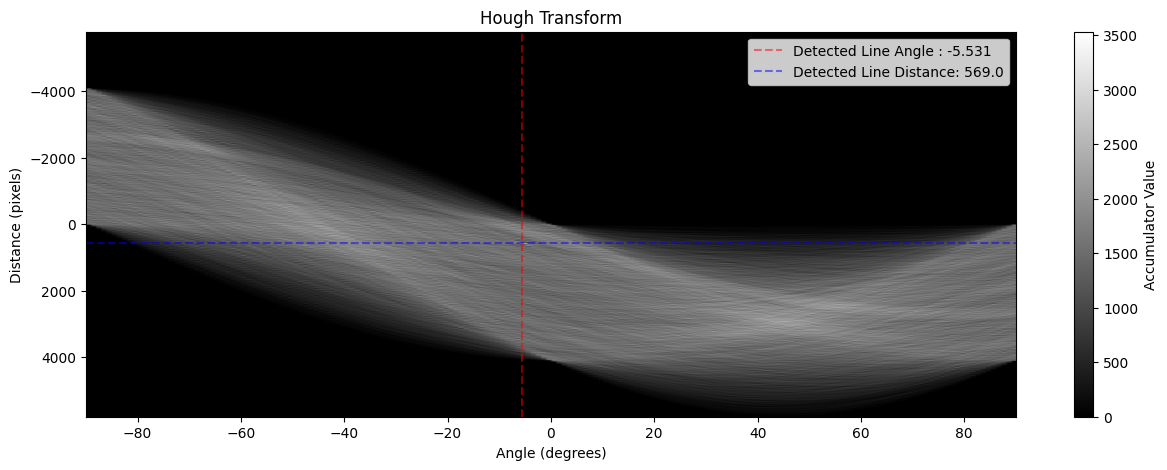

In [99]:
## Visualizing the Hough Space
plt.figure(figsize=(15, 5))

plt.imshow(hspace, extent=(np.rad2deg(angles[0]), np.rad2deg(angles[-1]), dists[-1], dists[0]),
           cmap='gray', aspect='auto')
plt.title('Hough Transform')
plt.xlabel('Angle (degrees)')
plt.ylabel('Distance (pixels)')
plt.colorbar(label='Accumulator Value')
plt.axvline(x=np.rad2deg(q), color='red', linestyle='--', label=f'Detected Line Angle : {np.round(np.rad2deg(q[0]), 3)}', alpha=0.5)
plt.axhline(y=d, color='blue', linestyle='--', label=f'Detected Line Distance: {d[0]}', alpha=0.5)

plt.legend()
plt.show()

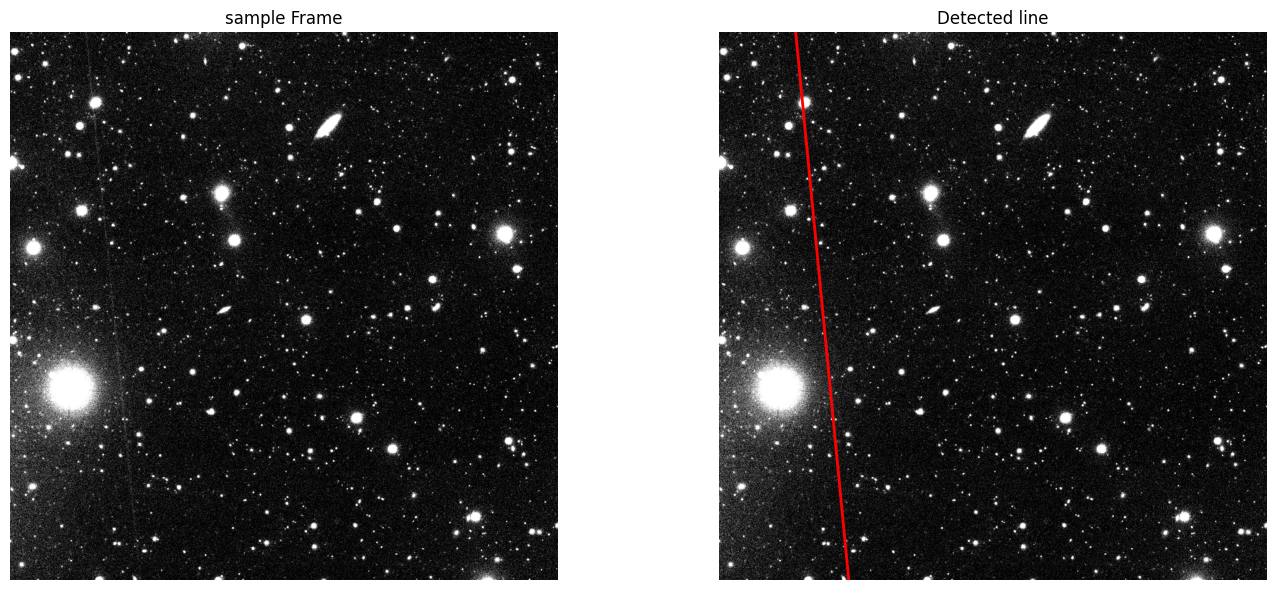

In [100]:
## Plot the detected line on the Sample frame:

fig, ax = plt.subplots(1, 2, figsize=(15, 6))


# Processed Frame
ax[0].imshow(image_sample_pre_processed, cmap='gray', vmax = 1, vmin = 0)
ax[0].set_title('sample Frame')
ax[0].set_axis_off()


# Processed frame, overlayed with the detected line
ax[1].imshow(image_sample_pre_processed, cmap='gray',  vmax = 1, vmin = 0)
origin_ = np.array((0, image_sample_pre_processed.shape[1]))
for _, angle, dist in zip(*transform.hough_line_peaks(hspace, angles, dists,num_peaks=1)):
    y0, y1 = (dist - origin_ * np.cos(angle)) / np.sin(angle)
    ax[1].plot(origin_, (y0, y1), '-r', alpha = 1.0, linewidth=2, label=f'Angle: {np.rad2deg(angle):.2f}°')
ax[1].set_xlim(origin_)
ax[1].set_ylim((image_sample_pre_processed.shape[0], 0))
ax[1].set_axis_off()
ax[1].set_title('Detected line')

plt.tight_layout()
plt.show()


## Step 4: Extract the Local region of Interest (Local Region of the detected streak)

In [101]:
## Functions to extract the start and end (intersection) points of the line detected on the Image plane

def estimate_start_end_points(img, angle , dist):
    height , width = img.shape

    # list to store the potential intersection points
    points = []

    # Handle horizontal clipping (x = 0 and x = width - 1)
    for x in [0, width - 1]:
        if np.sin(angle) != 0:
            y = (dist - x * np.cos(angle)) / np.sin(angle)
            if 0 <= y < height:
                points.append((x, int(y)))

    # Handle vertical clipping (y = 0 and y = height - 1)
    for y in [0, height - 1]:
        if np.cos(angle) != 0:
            x = (dist - y * np.sin(angle)) / np.cos(angle)
            if 0 <= x < width:
                points.append((int(x), y))

    if len(points) >= 2:
        return points[:2]

    else:
        return None


## Extracting the streak local region
def extract_streak_patch(image, start_point, end_point, box_width=100, output_length=None):

    # Direction and normalization
    start = np.array(start_point, dtype=np.float32)
    end = np.array(end_point, dtype=np.float32)
    direction = end - start
    length = np.linalg.norm(direction)

    if length == 0:
        raise ValueError("Start and end points are the same. Cannot define streak direction.")
    unit_direction = direction / length

    # Perpendicular vector
    perp = np.array([-unit_direction[1], unit_direction[0]])
    half_width = box_width / 2.0
    offset = perp * half_width

    # Bounding box corners
    corner1 = start + offset
    corner2 = start - offset
    corner3 = end - offset
    corner4 = end + offset
    bbox_points = np.array([corner1, corner2, corner3, corner4], dtype=np.float32)

    # Set output size
    patch_width = int(box_width)
    if output_length is None:
        output_length = int(length)

    # Grid in destination (rectified patch)
    dst_x, dst_y = np.meshgrid(np.linspace(0, 1, output_length),
                               np.linspace(0, 1, patch_width))
    dst_x_flat = dst_x.flatten()
    dst_y_flat = dst_y.flatten()

    # Interpolate within bbox corners
    top = bbox_points[0] + (bbox_points[3] - bbox_points[0]) * dst_x_flat[:, None]
    bottom = bbox_points[1] + (bbox_points[2] - bbox_points[1]) * dst_x_flat[:, None]
    src_pts = top + (bottom - top) * dst_y_flat[:, None]

    # Clamp to image bounds
    src_x = np.clip(src_pts[:, 0], 0, image.shape[1] - 1)
    src_y = np.clip(src_pts[:, 1], 0, image.shape[0] - 1)

    # Sample patch using bilinear interpolation
    patch = map_coordinates(image, [src_y, src_x], order=1, mode='reflect')
    patch = patch.reshape((patch_width, output_length))

    return patch, bbox_points

In [102]:
### Extracting the Local region of Interest

# Estimating intersection points in the frame for the detected streak
start_point, end_point = estimate_start_end_points(data, angle , dist)

# Extract the streak patch from the original frame
streak_patch, bbox_points = extract_streak_patch(
    data, start_point, end_point, box_width=150
)

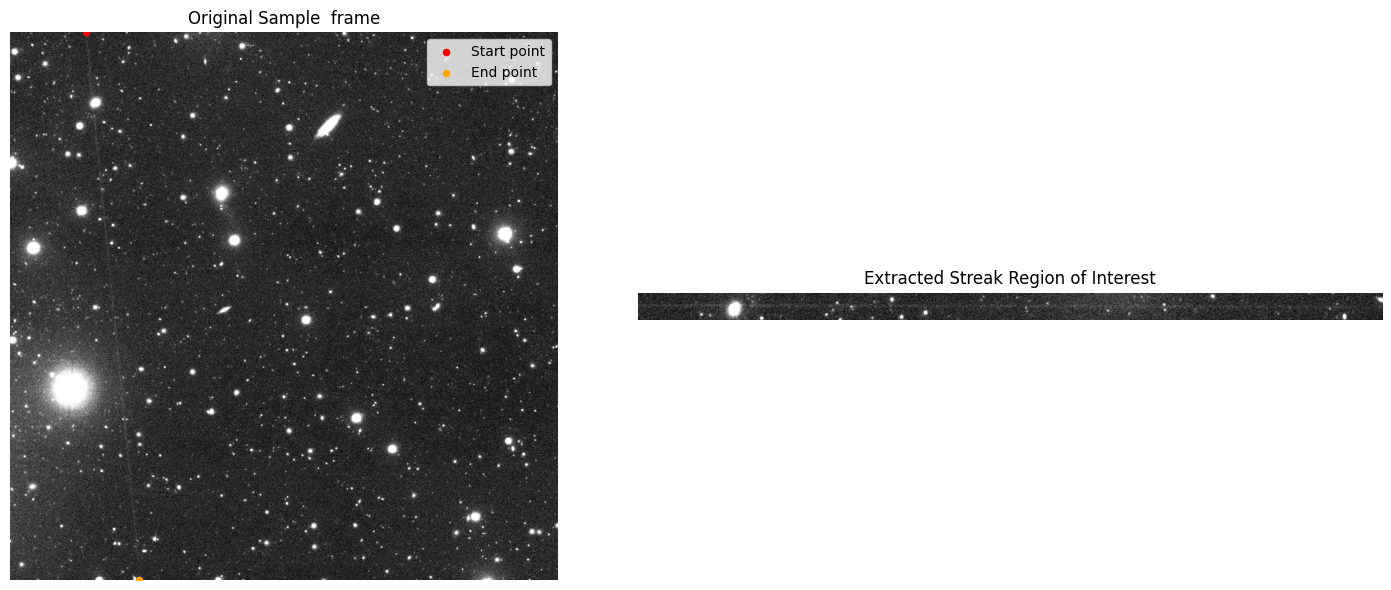

In [103]:
# Visualize the extracted streak patch along with the original Image:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Original image
axes[0].imshow(data, cmap='gray',vmin=median-1*std, vmax=median+5*std )
axes[0].scatter(start_point[0], start_point[1], c = 'red', s = 20, label = 'Start point')
axes[0].scatter(end_point[0], end_point[1], c = 'orange', s = 20, label = 'End point')
axes[0].set_title('Original Sample  frame')
axes[0].axis('off')
axes[0].legend()


# Streak patch
axes[1].imshow(streak_patch, cmap='gray', vmin=median-1*std, vmax=median+5*std)
axes[1].set_title('Extracted Streak Region of Interest')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# PART B: STREAK CHARACTERIZATION

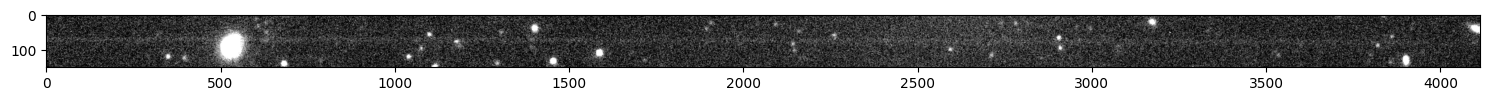

In [104]:
## Visualize the Region of Interest
plt.figure(figsize=(15, 3))
plt.imshow(streak_patch, cmap = 'gray', vmin=median-1*std, vmax=median+5*std)
plt.tight_layout()
plt.show()

## 1. Length Estimation

In [105]:
### Functions to perform Length Estimation ######

# Function to generate the edge using Laplacian of Gaussian (LoG) method
def log_edge_detection(image, sigma=15):
    """
    Perform edge detection using the Laplacian of Gaussian (LoG) method.
    """
    # Apply the Laplacian of Gaussian filter
    log_image = gaussian_laplace(image, sigma=sigma)

    # Threshold the LoG image to create a binary edge map
    threshold = np.mean(log_image)
    edges = log_image < threshold

    return edges

# Hough Transform based line detection
def detect_streaks_with_hough(edges, line_length=500, line_gap=40, threshold=100):
    """
    Perform Lines detections in the Region of interest
    """
    # Apply Hough Transform to detect lines
    lines = transform.probabilistic_hough_line(edges,
                                               threshold=threshold,
                                               line_length=line_length,
                                               line_gap=line_gap)
    return lines

# Group the lines detected based on tolerances given for slope and the intercept
def group_lines_by_slope_intercept(lines, slope_tolerance=1.5, intercept_tolerance=15):
    """
    Group lines based on their slope and intercept with given tolerances.

    """
    def calculate_slope_intercept(line):
        (x1, y1), (x2, y2) = line
        if x2 - x1 == 0:
            slope = float('inf')
            intercept = x1
        else:
            slope = (y2 - y1) / (x2 - x1)
            intercept = y1 - slope * x1
        return slope, intercept

    def is_similar(line1, line2):
        slope1, intercept1 = calculate_slope_intercept(line1)
        slope2, intercept2 = calculate_slope_intercept(line2)
        angle_diff = np.abs(np.degrees(np.arctan(slope1)) - np.degrees(np.arctan(slope2)))
        intercept_diff = np.abs(intercept2 - intercept1)
        return angle_diff <= slope_tolerance and intercept_diff <= intercept_tolerance

    groups = []
    for line in lines:
        added = False
        for group in groups:
            if is_similar(line, group[0]):
                group.append(line)
                added = True
                break
        if not added:
            groups.append([line])

    return groups


# Estimating the global_start and global_End of the line segments for the detected lines
def estimate_extents(group_lines):
    all_points = []

    for i in group_lines:
        (x1, y1), (x2, y2) = i
        all_points.append([x1, y1])
        all_points.append([x2, y2])

    # sort all the points based on the x-axis. with increasing order.
    all_points.sort(key = lambda x: x[0])

    min_x = all_points[0][0]
    min_y = all_points[0][1]
    max_x = all_points[-1][0]
    max_y = all_points[-1][1]

    # Calculate the angle of the detected line
    slope = np.arctan2(max_y - min_y, max_x - min_x)
    slope = np.degrees(slope)

    return [min_x, min_y] , [max_x, max_y] , slope


In [106]:
### APPLYTING THE ALGORITHM

# Perform edge detection using Laplacian of Gaussian
edges = log_edge_detection(streak_patch, sigma=10)

# Detect streaks using Hough Transform
lines = detect_streaks_with_hough(edges, line_length=400, line_gap=25, threshold=500)

# Group lines based on slope and intercept
grouped_lines = group_lines_by_slope_intercept(lines, slope_tolerance=1, intercept_tolerance=15)

## sort the grouped_lines based on the maximum number of lines in each group.
grouped_lines.sort(key = lambda x: len(x), reverse = True)
group = grouped_lines[0]

## Get the extent of the detected line
min_point , max_point , slope = estimate_extents(group)

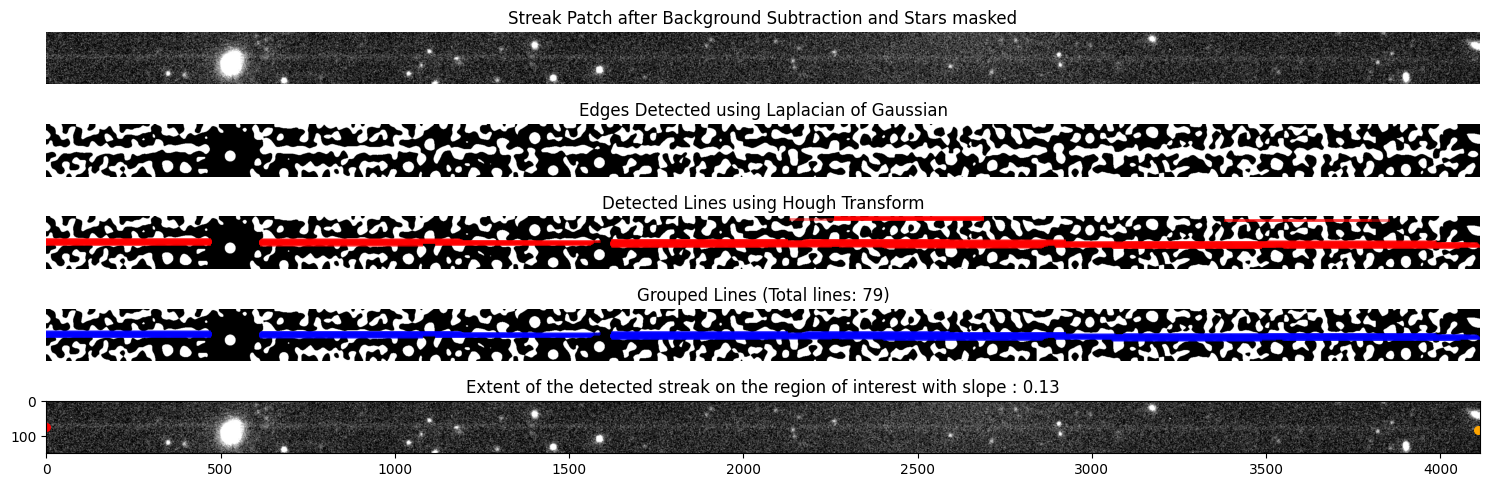

In [107]:
## Visualizing the results
fig, ax = plt.subplots(5,1, figsize=(15, 5))

# Visualize the masked region of interest
ax[0].imshow(streak_patch, cmap='gray', vmin=median-1*std, vmax=median+5*std)
ax[0].set_title('Streak Patch after Background Subtraction and Stars masked')
ax[0].axis('off')

# Visualize the edges detected
ax[1].imshow(edges, cmap='gray')
ax[1].set_title("Edges Detected using Laplacian of Gaussian")
ax[1].axis('off')


# Visualize the detected lines on the edges
ax[2].imshow(edges, cmap='gray')
for line in lines:
    p0, p1 = line
    ax[2].plot([p0[0], p1[0]], [p0[1], p1[1]], color='red', linewidth=2, alpha=0.5)
ax[2].set_title("Detected Lines using Hough Transform")
ax[2].axis('off')

# Visualize the grouped lines
ax[3].imshow(edges, cmap='gray')
for line in group:
    p0, p1 = line
    ax[3].plot([p0[0], p1[0]], [p0[1], p1[1]], color='blue', linewidth=2, alpha=0.5)
ax[3].set_title(f"Grouped Lines (Total lines: {len(group)})")
ax[3].axis('off')

# Visualize the extent of the detected line
ax[4].imshow(streak_patch, cmap='gray', vmin=median-1*std, vmax=median+5*std)
ax[4].scatter(min_point[0], min_point[1], c = 'red', s= 30)
ax[4].scatter(max_point[0], max_point[1], c = 'orange', s= 30)
ax[4].set_title(f'Extent of the detected streak on the region of interest with slope : {np.round(slope,2)}')

plt.tight_layout()
plt.show()

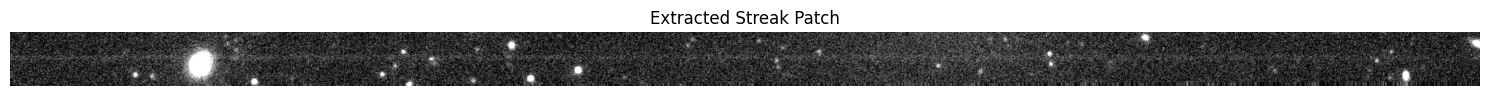

In [108]:
## Extract the streak patch using the min and max points:
streak_patch_estimated_length, bbox_points = extract_streak_patch(
    streak_patch, min_point, max_point, box_width=150
)

# Visualize the extracted streak patch
fig, ax = plt.subplots(figsize=(15, 3))
ax.imshow(streak_patch_estimated_length, cmap='gray', vmin=median-1*std, vmax=median+5*std, origin = 'lower')
ax.set_title("Extracted Streak Patch")
ax.axis('off')
plt.tight_layout()
plt.show()

In [109]:
## Estimating Length

# Method 1: Longitudinal axis of the image is itself the length
length_method_1  = streak_patch_estimated_length.shape[1]
print(f'Length estimated using method 1 : {length_method_1} pixels')


# Method 2: Euclidean distance formula using min and max points
length_method_2 = np.sqrt((max_point[0] - min_point[0])**2 + (max_point[1] - min_point[1])**2)
print(f'Length estimated using method 2 : {length_method_2} pixels')


Length estimated using method 1 : 4108 pixels
Length estimated using method 2 : 4108.009858800244 pixels


## 2. Width Estimation

In [110]:
########## FUNCTIONS TO PERFORM WIDTH ESTIMATION ################

## Function to perform Normalization
def normalize_data(profile):
    profile -= np.min(profile)
    return profile/np.max(profile)

## Fitting Gaussian Profile to get the standard deviation of the streak region
def gaussian(x, a, mu, sigma):
    return a * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

def fit_gaussian_to_peak(median_profile, window_half_width=20):

    x = np.arange(len(median_profile))
    peak_idx = np.argmax(median_profile)

    # Define fitting window around the peak
    start = max(0, peak_idx - window_half_width)
    end = min(len(median_profile), peak_idx + window_half_width)
    x_fit = x[start:end]
    y_fit = median_profile[start:end]

    # Initial guesses
    a0 = np.max(y_fit)
    mu0 = x_fit[np.argmax(y_fit)]
    sigma0 = 5  # Initial width guess, can tweak

    # Fit  Gaussian
    try:
        popt, _ = curve_fit(gaussian, x_fit, y_fit, p0=[a0, mu0, sigma0])
        a, mu, sigma = popt
        fit_curve = gaussian(x_fit, *popt)
        return a, mu, sigma, fit_curve, x_fit
    except RuntimeError:
        print("Gaussian fit failed.")
        return None, None, None, None, None


def width_estimation(streak_region, n_sigma = 2):

    # Extract Row - wise Median
    profile = np.median(streak_region , axis = 1)

    # Normalize profile
    profile = normalize_data(profile)

    # Fit Gaussian to the noramalized profile
    a, mu, sigma, fit_curve, x_fit = fit_gaussian_to_peak(profile, window_half_width=13)

    if sigma is not None and sigma < 23:

        # Calculating lower and upper bounds
        lower_bound = int(mu - n_sigma * sigma)
        upper_bound = int(mu + n_sigma * sigma)

        # Ensure bounds are within the image dimensions
        lower_bound = max(lower_bound, 0)
        upper_bound = min(upper_bound, streak_region.shape[0] - 1)

        # Width
        width = upper_bound - lower_bound

        fit_data_dict = {
            "profile": profile,
            "amplitude":a,
            "mean":mu,
            "sigma":sigma,
            "fit_curve":fit_curve,
            "x_fit":x_fit,
            "lower_bound":lower_bound,
            "upper_bound":upper_bound,
            "width": width
        }

        return fit_data_dict
    else:
        return None

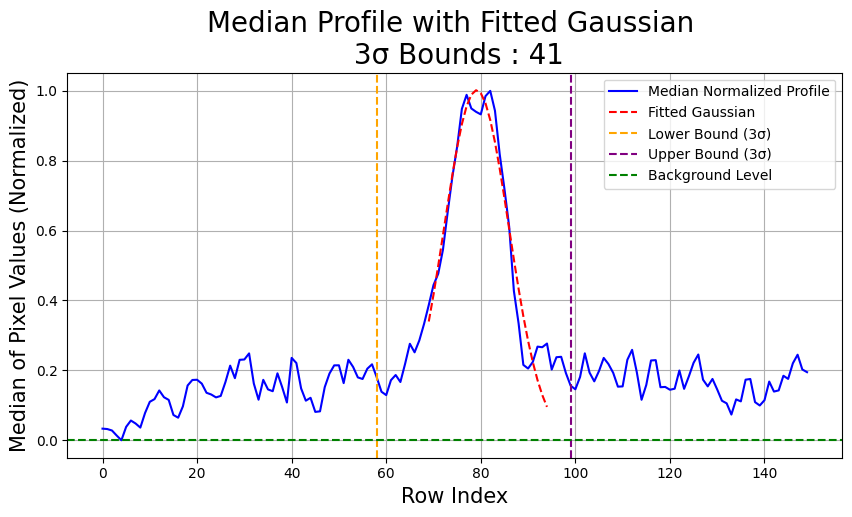

In [111]:
# Perform Width estimation
fit_results  = width_estimation(streak_patch_estimated_length ,n_sigma = 3 )


## Visualize the fitted Gaussian on the profile
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(fit_results['profile'], label='Median Normalized Profile', color='blue')
ax.plot(fit_results['x_fit'], fit_results['fit_curve'], label='Fitted Gaussian', color='red', linestyle='--')

ax.axvline(fit_results["lower_bound"], color='orange', linestyle='--', label='Lower Bound (3σ)')
ax.axvline(fit_results["upper_bound"], color='purple', linestyle='--', label='Upper Bound (3σ)')
ax.axhline(0, color='green', linestyle='--', label='Background Level')
ax.set_title(f"Median Profile with Fitted Gaussian \n 3σ Bounds : {fit_results["width"]}", fontsize  = 20)
ax.set_xlabel("Row Index",fontsize  = 15)
ax.set_ylabel(f"Median of Pixel Values (Normalized)", fontsize  = 15)
ax.grid()
ax.legend()
plt.show()

In [112]:
#  Function to extract the exact region of the streak with estimated width having the extent of lower and upper bounds

def extract_streak_region(image, lower_bound, upper_bound):
    return image[lower_bound:upper_bound + 1, :]

# Extract the streak region using the lower and upper bounds
streak_region_width_length_estimated = extract_streak_region(streak_patch_estimated_length, fit_results["lower_bound"], fit_results["upper_bound"])

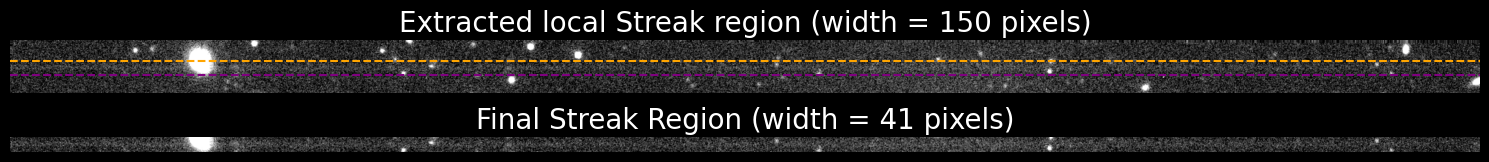

In [113]:
## Visualize the lower and upper bounds on the extracted streak region and the final streak region:
fig, ax = plt.subplots(2, 1, figsize=(15, 2))
fig.patch.set_facecolor('black')
# Visualize the extracted streak region with bounds
ax[0].imshow(streak_patch_estimated_length, cmap='gray', vmin=median-1*std, vmax=median+5*std)
ax[0].axhline(fit_results["lower_bound"], color='orange', linestyle='--', label='Lower Bound (2σ)')
ax[0].axhline(fit_results["upper_bound"], color='purple', linestyle='--', label='Upper Bound (2σ)')
ax[0].set_title(f"Extracted local Streak region (width = {streak_patch_estimated_length.shape[0]} pixels)", color='white', fontsize  = 20)
ax[0].axis('off')

# Visualize the final streak region
ax[1].imshow(streak_region_width_length_estimated, cmap='gray', vmin=median-1*std, vmax=median+5*std)
ax[1].set_title(f"Final Streak Region (width = {fit_results['width']} pixels)", color='white',  fontsize  = 20)
ax[1].axis('off')
plt.tight_layout()
plt.show()

## 3. SNR Estimation : Signal to Noise ration using total flux integration method

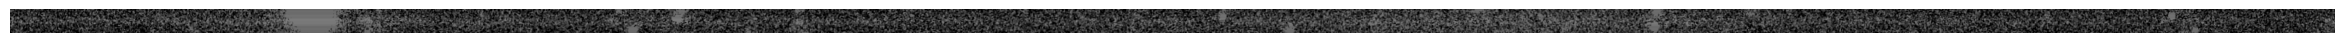

In [114]:
# Function to Mask the bright Stars

def mask_star(img):
    """
    Replace high-intensity pixels (>95th percentile per row)
    with the median of that row.

    """

    # Copy image to avoid modifying original
    corrected_img = np.array(img, copy=True)

    # Loop over all rows
    for i in range(corrected_img.shape[0]):
        row = corrected_img[i, :]

        # Compute 90th percentile and median
        percentile_95 = np.percentile(row, 95)
        row_median = np.median(row)

        # Replace bright pixels
        mask = row > percentile_95
        corrected_img[i, mask] = percentile_95

    return corrected_img


## Masking the bright stars/pixels
streak_region_masked = mask_star(streak_region_width_length_estimated)


# visualization of masked region
plt.figure(figsize = (30, 5))
plt.imshow(streak_region_masked , cmap='gray', vmin=median-1*std, vmax=median+5*std  )
plt.axis('off')
plt.show()

In [115]:
## Functions to calculate the SNR through simple noise model.

# Estimating the Error pixel Wise
def calculate_error(image, gain=4.0, rdnoise=6.0):
    """
    Calculate per-pixel noise (std dev) in ADU, including shot + read noise.

    """

    # Ensure non-negative signal for Poisson statistics
    signal_adu = np.clip(image, 0, None)

    # Convert to electrons
    signal_e = gain * signal_adu

    # Total variance in electrons
    variance_e = signal_e + rdnoise**2

    # Convert to ADU
    std_adu = np.sqrt(variance_e) / gain

    return std_adu


# Compute SNR From the Masked region
def compute_signal_and_snr(masked_image, sky, gain=4.0, rdnoise=6.0):
    """
    Compute total integrated signal and SNR from a masked astronomical image.

    """

    # Ensure numpy arrays
    img = np.array(masked_image, dtype=float)

    # Subtract sky background
    signal_adu = img - sky

    # SIGNAL
    # Total integrated signal in electrons
    signal_e = np.sum(signal_adu * gain)

    # NOISE MODEL
    error_map  = calculate_error(streak_region_masked)
    variance_e = (np.sum((error_map) **2 * gain**2 ))
    noise_e = np.sqrt(variance_e)
    noise_adu = noise_e / gain

    # SNR
    flux_adu = np.sum(signal_adu)
    snr = flux_adu / noise_adu if noise_adu != 0 else 0

    return {
        "signal_e": signal_e,
        "variance_e": variance_e,
        "noise_e": noise_e,
        "noise_adu": noise_adu,
        "flux_adu":flux_adu,
        "snr": snr
    }

In [116]:
## Estimating the Total Flux and the Integrated SNR
get_photometric_estimates = compute_signal_and_snr(streak_region_masked, sky)

print (f'''
Total Integrated Flux   : {get_photometric_estimates['flux_adu']}
Total Integrated SNR    : {get_photometric_estimates['snr']}

''')


Total Integrated Flux   : 1143691.8790087781
Total Integrated SNR    : 135.31979813597545




## 4. Visualize the Position of Detected Streak in the Sample Frame

In [ ]:
## Function to get corners for the bounding box:
def get_bounding_box(start_point, end_point, half_width=10, shift_along_axis=0):
    """
    Compute a rotated bounding box around a line segment, with optional
    longitudinal shift, and return its centroid.

    """

    # Convert to numpy
    start = np.array(start_point, dtype=np.float32)
    end = np.array(end_point, dtype=np.float32)

    # Direction vector
    direction = end - start
    length = np.linalg.norm(direction)

    if length == 0:
        raise ValueError("Start and end points are the same.")

    # Unit direction
    unit_direction = direction / length

    # Shift along longitudinal axis
    shift_vector = unit_direction * shift_along_axis
    start_shifted = start + shift_vector
    end_shifted = end + shift_vector

    # Perpendicular direction
    perp = np.array([-unit_direction[1], unit_direction[0]])

    # Width offset
    offset = perp * half_width

    # Corners
    corner1 = start_shifted + offset
    corner2 = start_shifted - offset
    corner3 = end_shifted - offset
    corner4 = end_shifted + offset

    bbox_points = np.array(
        [corner1, corner2, corner3, corner4],
        dtype=np.int32
    )

    # midpoint of segment
    centroid = (start_shifted + end_shifted) / 2

    return bbox_points, [int(i) for i in centroid]


def interpolate_line_pixels(start_point, end_point, rotation_angle=0, image=None, line_length=None):
    """
    Interpolates pixel values along a line defined by its start and end points, rotates the line by a given angle,
    and optionally clips the line to a specified length from the starting point. Ensures the coordinates are within
    the bounds of the provided image.
    """
    x1, y1 = start_point
    x2, y2 = end_point

    # Calculate the total distance between start and end points
    total_distance = np.hypot(x2 - x1, y2 - y1)

    # If line_length is provided, clip the line to the specified length
    if line_length is not None and line_length < total_distance:
        # Calculate the direction vector and normalize it
        direction_vector = np.array([x2 - x1, y2 - y1]) / total_distance
        # Calculate the new end point based on the clipped length
        x2 = x1 + direction_vector[0] * line_length
        y2 = y1 + direction_vector[1] * line_length

    # Calculate the number of points to interpolate based on the distance between points
    num_points = int(np.hypot(x2 - x1, y2 - y1)) + 1

    # Interpolate x and y coordinates
    x_coords = np.linspace(x1, x2, num_points)
    y_coords = np.linspace(y1, y2, num_points)

    # Rotate the line by the given angle
    angle_rad = np.radians(-rotation_angle)
    center_x = (x1 + x2) / 2
    center_y = (y1 + y2) / 2

    x_rotated = center_x + (x_coords - center_x) * np.cos(angle_rad) - (y_coords - center_y) * np.sin(angle_rad)
    y_rotated = center_y + (x_coords - center_x) * np.sin(angle_rad) + (y_coords - center_y) * np.cos(angle_rad)

    # If an image is provided, constrain the coordinates within its bounds
    if image is not None:
        height, width = image.shape
        x_rotated = np.clip(x_rotated, 0, width - 1)
        y_rotated = np.clip(y_rotated, 0, height - 1)

    return x_rotated.astype(int), y_rotated.astype(int)



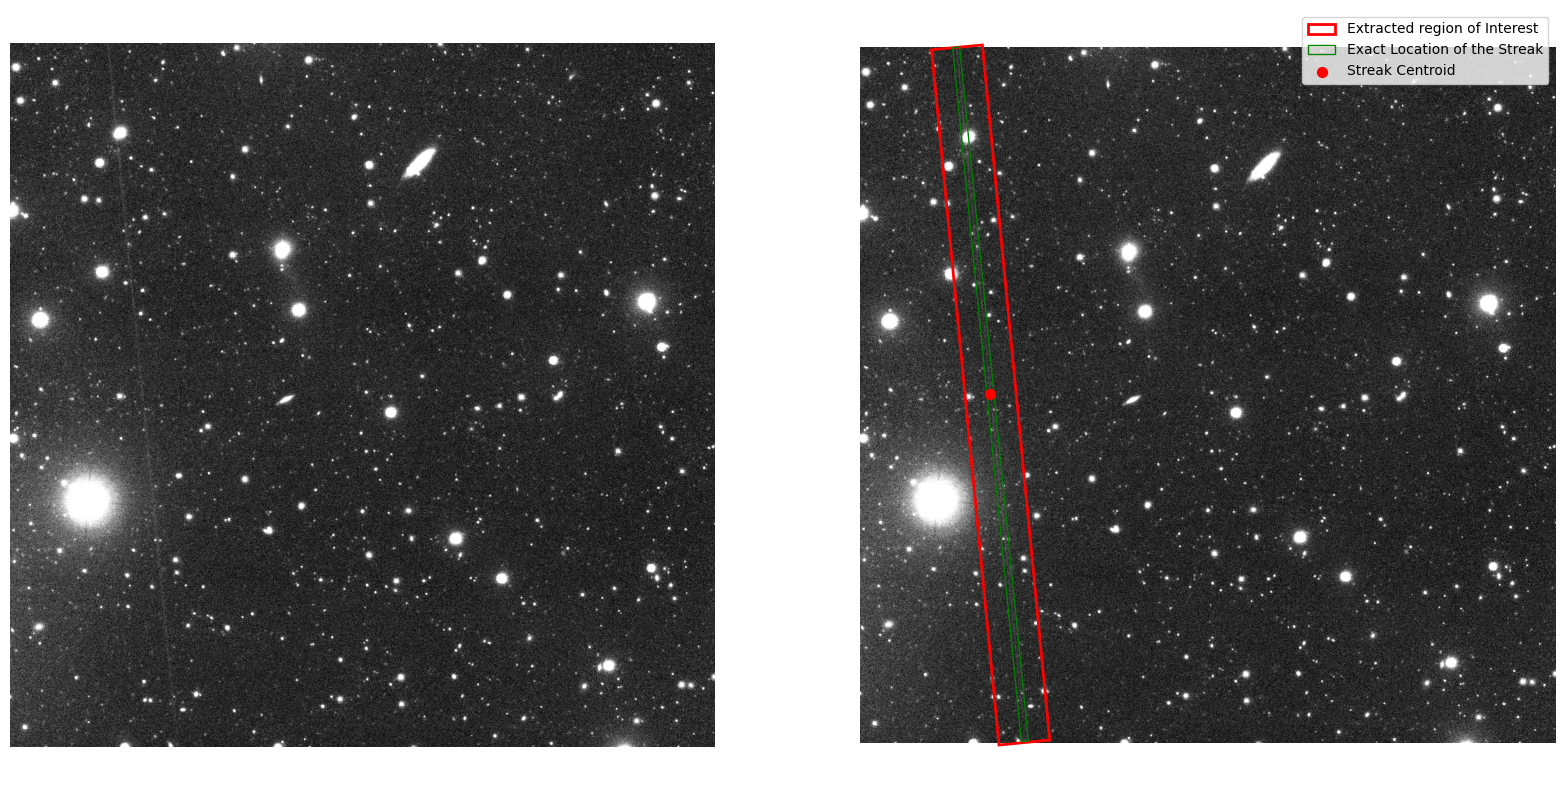

In [118]:
# Calculate the Length of the streak
length = streak_region_masked.shape[1]

## Get the interpolated pixel values along the line defined by the start and end points
x_coords, y_coords = interpolate_line_pixels(start_point, end_point, slope, data, length)

# Get the bounding box points
bbox_points_larger_box, _ = get_bounding_box(start_point, end_point, half_width=150)

# Get the inner bounding box points
bbox_points_inner_box, centroid = get_bounding_box((x_coords[0], y_coords[0]),(x_coords[-1], y_coords[-1]), half_width=fit_results['width']/2, shift_along_axis=min_point[0])



######## Plotting the original image
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

#### Original frame
ax[0].imshow(data, cmap='gray', vmin=median-1*std, vmax=median+5*std )
ax[0].axis('off')


#### Original frame overlayed with region of interset, location of streak and the centroid
ax[1].imshow(data, cmap='gray', vmin=median-1*std, vmax=median+5*std )
## Create a polygon from the outer bounding box points
bbox_polygon_outer = Polygon(bbox_points_larger_box, closed=True, fill=False, edgecolor='red', linewidth=2, label = 'Extracted region of Interest')
ax[1].add_patch(bbox_polygon_outer)
## Create a polygon from the inner bounding box points
bbox_polygon_inner = Polygon(bbox_points_inner_box, closed=True, fill=False, edgecolor='green', linewidth=1, label = "Exact Location of the Streak")
ax[1].add_patch(bbox_polygon_inner)
## Centroid of the detected streak
ax[1].scatter(centroid[0], centroid[1], c = 'red', s = 50, label = 'Streak Centroid')

plt.legend()
plt.axis('off')
plt.show()

________________________________

# PART C: Detection and Characterization for a set of Samples

In [45]:
## Load the directory in the colab Runtime

# Public dataset contains a few samples with streaks
gdrive_dir_path_id = '1xOvv7oylcozGWUI-oBNJ8akYv3XeiVNV'

# Download folder data
gdown.download_folder(id=gdrive_dir_path_id, output='data', quiet=True, use_cookies=False)

['data/20221023-0057.fits',
 'data/20230310-0010.fits',
 'data/20230313-0014.fits',
 'data/20230313-0015.fits',
 'data/20230326-0028.fits',
 'data/20230414-0016.fits',
 'data/20230514-0031.fits',
 'data/20230607-0011.fits',
 'data/20230615-0006.fits',
 'data/20230615-0012.fits',
 'data/20230615-0022.fits']

In [47]:
# path of directory containing samples
dir_path = r"/content/data"

files  = os.listdir(dir_path)
files = [i for i in files if  ".fits" in i] ## Selecting only fits files
files

['20230310-0010.fits',
 '20230313-0015.fits',
 '20230615-0006.fits',
 '20230326-0028.fits',
 '20230313-0014.fits',
 '20230615-0012.fits',
 '20221023-0057.fits',
 '20230607-0011.fits',
 '20230414-0016.fits',
 '20230514-0031.fits',
 '20230615-0022.fits']

In [48]:
## Looping through all files

# Empty list to hold properties of the detected Streaks
properties_list = []

for i in files:

    ##-------------- Loading frame -----------------------##
    frame_path = os.path.join(dir_path , i)
    with fits.open(frame_path) as hdul:
        data = hdul[0].data
        header = hdul[0].header
        # Adding Sky background
        data += header.get('SKY', 1180)

    ################## ------- STREAK DETECTION ----------------##########################

    ##------------- Image Pre-Processing ------------------##
    # Median Filtering
    image_sample_denoised  = remove_cosmic_rays(data)

    # Perform dynamic thresholding
    image_sample_pre_processed, med_sample, std_sample= process_image(image_sample_denoised)


    ## ------------ EDGE Detection ------------------------##
    # Perform Edge detection
    sample_edge = log_edge_detection(image_sample_pre_processed)

    ## ----------- Hough Transform -----------------------##
    hspace, angles, dists , h, q , d = perform_hough_transform(sample_edge)

    ## ----------- Extract Local Region of Interest-------------##
    # Estimating intersection points in the frame for the detected sterak
    start_point, end_point = estimate_start_end_points(data, q , d)

    # Extract the streak patch from the orginal frame
    streak_patch, bbox_points = extract_streak_patch(
        data, start_point, end_point, box_width=150
    )

    ################## ------- STREAK Characterization ----------------##########################

    ## ------------------------- Length Estimation -------------------------------------##

    # Perform edge detection using Laplacian of Gaussian
    edges = log_edge_detection(streak_patch, sigma=10)

    # Detect streaks using Hough Transform
    lines = detect_streaks_with_hough(edges, line_length=400, line_gap=25, threshold=1000)

    if len(lines) < 10:
        continue

    # Group lines based on slope and intercept
    grouped_lines = group_lines_by_slope_intercept(lines, slope_tolerance=1, intercept_tolerance=10)

    ## sort the grouped_lines based on the maximum number of lines in each group.
    grouped_lines.sort(key = lambda x: len(x), reverse = True)
    group = grouped_lines[0]

    ## Get the extent of the detected line
    min_point , max_point , slope = estimate_extents(group)

    ## Extract the streak patch using the min and max points:
    streak_patch_estimated_length, bbox_points = extract_streak_patch(
        streak_patch, min_point, max_point, box_width=150
    )

    ## ------------------------- Width Estimation -------------------------------------##
    # Perform Width estimation
    fit_results  = width_estimation(streak_patch_estimated_length ,n_sigma = 2 )

    try:
        if fit_results['sigma'] < 20:
            # Extract the streak region using the lower and upper bounds
            streak_region_width_length_estimated = extract_streak_region(streak_patch_estimated_length, fit_results["lower_bound"], fit_results["upper_bound"])

    except:
        continue


    ## ------------------------- Total Flux & SNR Estimation -------------------------------------##

    # Masking bright sources such as stars  and Elongated Galaxies
    streak_region_masked = mask_star(streak_region_width_length_estimated)

    # calculating Flux and SNR
    get_photometric_estimates = compute_signal_and_snr(streak_region_masked, header.get('SKY', 1180))

    ## ------------------------- Centroid Estimation -----------------------------##
    # Get the interpolated pixel values along the line defined by the start and end points
    x_coords, y_coords = interpolate_line_pixels(start_point, end_point, slope, data, streak_region_masked.shape[1])
    # Get the inner bounding box points
    _, centroid = get_bounding_box((x_coords[0], y_coords[0]),(x_coords[-1], y_coords[-1]), half_width=fit_results['width']/2, shift_along_axis=min_point[0])


    ## -------------------------- Collecting Properties -----------------------------##
    feautures_dict = {
        "frame_Id"              : i.split('.')[0],
        "obs_filter"            : header['FILTER'],
        "centroid"              : centroid,
        "Length_estimated_pix"  : streak_patch_estimated_length.shape[1],
        "Width_estimated_pix"   : fit_results['width'],
        "Total_signal_flux"     : np.round(get_photometric_estimates['flux_adu'],3),
        "Estimated_SNR"         : np.round(get_photometric_estimates['snr'],2)

    }

    print (feautures_dict)

    # appending features extracted in the properties list
    properties_list.append(feautures_dict)


    # break


{'frame_Id': '20230310-0010', 'obs_filter': 'i', 'centroid': [3099, 1111], 'Length_estimated_pix': 2423, 'Width_estimated_pix': 39, 'Total_signal_flux': np.float64(280660.748), 'Estimated_SNR': np.float64(67.43)}
{'frame_Id': '20230313-0015', 'obs_filter': 'i', 'centroid': [2057, 107], 'Length_estimated_pix': 4080, 'Width_estimated_pix': 38, 'Total_signal_flux': np.float64(1549212.314), 'Estimated_SNR': np.float64(183.75)}
{'frame_Id': '20230615-0006', 'obs_filter': 'r', 'centroid': [1491, 1372], 'Length_estimated_pix': 4030, 'Width_estimated_pix': 27, 'Total_signal_flux': np.float64(458377.435), 'Estimated_SNR': np.float64(98.13)}
{'frame_Id': '20230326-0028', 'obs_filter': 'i', 'centroid': [3129, 470], 'Length_estimated_pix': 2111, 'Width_estimated_pix': 62, 'Total_signal_flux': np.float64(1061298.068), 'Estimated_SNR': np.float64(170.42)}
{'frame_Id': '20230313-0014', 'obs_filter': 'i', 'centroid': [769, 2044], 'Length_estimated_pix': 4108, 'Width_estimated_pix': 28, 'Total_signal_f

In [49]:
import pandas as pd
df = pd.DataFrame.from_dict(properties_list)
display(df)

,frame_Id,obs_filter,centroid,Length_estimated_pix,Width_estimated_pix,Total_signal_flux,Estimated_SNR
0,20230310-0010,i,"[3099, 1111]",2423,39,280660.748,67.43
1,20230313-0015,i,"[2057, 107]",4080,38,1549212.314,183.75
2,20230615-0006,r,"[1491, 1372]",4030,27,458377.435,98.13
3,20230326-0028,i,"[3129, 470]",2111,62,1061298.068,170.42
4,20230313-0014,i,"[769, 2044]",4108,28,877985.926,124.99
5,20230615-0012,r,"[2043, 1449]",5002,14,643443.198,170.20
6,20230607-0011,g,"[1748, 1553]",3203,35,2349728.421,410.43
7,20230615-0022,r,"[2309, 201]",3585,13,5533656.251,1458.90
